In [2]:
#Nov. 4, 2026 @ 7.20 pm
#Once more Logistic Regression with ChatGPT

The system predicts the likelihood of a candidate receiving a job offer based on academic performance, technical skills, experience, company requirements, and other candidate-related factors.

We will continue using status as our target variable.

One important distinction: Receiving an offer does not necessarily mean accepting or joining the job. We'll keep that distinction clear in our project findings and dashboard.

Business-focused ML modeling includes:
Defining status as the target variable


Placed → Job Accepted (1)


Not Placed → Job Rejected (0)

One important distinction: The dataset labels alone do not establish whether an offer was actually accepted. Your mentor's mapping defines how the project intends to interpret them. If possible, confirm that interpretation with your mentor, because receiving an offer and accepting an offer are different outcomes.

When should we apply SMOTE?
Not during our current data-cleaning stage.

Our correct workflow will be:
1. Complete data cleaning and missing-value treatment.
2. Separate features (X) and target (y).
3. Split into training and testing datasets using stratification.
4. Encode categorical features and scale numerical features where appropriate.
5. Apply SMOTE only to the training data.
6. Train and evaluate models on untouched test data. 

Critical rule: Never apply SMOTE to the entire dataset before splitting. That can cause data leakage and misleading evaluation results.

For our mixed dataset containing numerical and categorical features, we should also consider SMOTENC, which is designed for mixed numerical and categorical data. 

5. One important clarification
Our dataset's target labels are Placed and Not Placed. The project title refers to job acceptance, but we should confirm what these labels mean before interpreting model predictions as actual offer acceptance or rejection.

My suggestion: Let's finish cleaning first. When we reach modelling, we'll build a baseline model, then compare class weighting and SMOTENC (if appropriate).

That way, we'll have evidence showing whether oversampling genuinely improves our model rather than applying SMOTE just because the dataset is imbalanced.

Our machine-learning target remains unchanged 


X = df_clean.drop(columns=['status'])

y = df_clean['status'].map({
    'Placed': 1,
    'Not Placed': 0
})

In [3]:
import pandas as pd
import numpy as np
import sklearn

print("Python environment is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python environment is working!
Pandas version: 3.1.0
NumPy version: 2.5.4
Scikit-learn version: 1.9.1


In [4]:
#print("Dataset shape:", df.shape)

#print("\nColumn names:")
#print(df.columns.tolist())

#print("\nPlacement status counts:")
#print(df['status'].value_counts(dropna=False))

#print("\nDuplicate rows:", df.duplicated().sum())

#print("\nMissing values:")
#print(df.isnull().sum().sum())

In [5]:
# Count duplicate rows
#duplicate_count = df.duplicated().sum()

# Remove duplicates temporarily for comparison
#df_unique = df.drop_duplicates()

#print("Original dataset shape:", df.shape)
#print("Dataset after removing duplicates:", df_unique.shape)

#print("\nPlacement distribution after removing duplicates:")
#print(df_unique['status'].value_counts()) # pyright: ignore[reportUndefinedVariable]

In [6]:
#df_unique.to_csv(
 #   'data/HR_Job_Placement_Dataset_Clean.csv',
  #  index=False
#)

#print("Clean dataset saved successfully!")
#print("Saved records:", len(df_unique))

Before cleaning a dataset, we need to understand:
- How many candidates are present?
- What information is available?
- Which columns are numerical and categorical?
- Are there missing values?
- Are the data types correct?

In [7]:
df = pd.read_csv('data/HR_Job_Placement_Dataset.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print('head-->', df.head())
print('columns:', df.columns)
print('dtypes:', df.dtypes)
print('info:', df.info())
print('sample:', df.sample(5))

Dataset loaded successfully!
Shape: (51500, 26)
head-->    age_years  gender  ssc_percentage  hsc_percentage  degree_percentage  \
0         27    Male       65.061656       83.842578          75.856526   
1         24    Male       67.885626       64.973305          73.093588   
2         33  Female       73.892471       68.834121          90.196460   
3         31    Male       74.145568       76.255126          75.586731   
4         28    Male       60.475937       65.786336          80.801010   

    degree_specialization  technical_score  aptitude_score  \
0        Computer Science        58.221909       89.566305   
1             Electronics        71.927978       54.591971   
2  Information Technology        72.445041       58.587088   
3              Mechanical        78.855676       61.022065   
4  Information Technology        68.286776       65.713731   

   communication_score  skills_match_percentage  ...  expected_ctc_lpa  \
0            64.474484                79.54891

2. Dataset information
Data type	Number of columns
Integer (int64)	3
Decimal (float64)	11
String (str)	12
Total	26

This is useful because machine-learning algorithms need numerical inputs. Later, we'll convert categorical columns into numerical representations using encoding. 

columns                        dtypes: 
age_years                      int64
gender                           str
ssc_percentage               float64
hsc_percentage               float64
degree_percentage            float64
degree_specialization            str
technical_score              float64
aptitude_score               float64
communication_score          float64
skills_match_percentage      float64
certifications_count           int64
internship_experience            str
years_of_experience            int64
career_switch_willingness        str
relevant_experience              str
previous_ctc_lpa             float64
expected_ctc_lpa             float64
company_tier                     str
job_role_match                   str
competition_level                str
bond_requirement                 str
notice_period_days           float64
layoff_history                   str
employment_gap_months        float64
relocation_willingness           str
status                           str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):

3. Important observation: Missing values
Your df.info() output reveals missing values in several columns.

For example:
Column	                        Non-null	Missing
ssc_percentage	                48,919	   2,581
hsc_percentage	                49,435	2,065
career_switch_willingness	    43,034	8,466
relevant_experience         	43,074	8,426
job_role_match	                45,369	6,131
layoff_history	                43,033	8,467
relocation_willingness	        43,025	8,475

Important: We should not fill or delete these missing values yet. First, we'll investigate their patterns and decide the appropriate treatment.

In [8]:
#Count missing values in every column
missing_values = df.isnull().sum()

print(missing_values.sort_values(ascending=False))

relocation_willingness       8475
layoff_history               8467
career_switch_willingness    8466
relevant_experience          8426
job_role_match               6131
ssc_percentage               2581
hsc_percentage               2065
notice_period_days           1582
employment_gap_months        1097
gender                          0
skills_match_percentage         0
communication_score             0
aptitude_score                  0
technical_score                 0
degree_specialization           0
degree_percentage               0
age_years                       0
internship_experience           0
company_tier                    0
expected_ctc_lpa                0
previous_ctc_lpa                0
years_of_experience             0
certifications_count            0
competition_level               0
bond_requirement                0
status                          0
dtype: int64


we need to know whether our target classes are balanced or imbalanced before selecting and evaluating machine-learning models.

In [9]:
df['status'].value_counts()

status
Not Placed    35921
Placed        15579
Name: count, dtype: int64

In [10]:
df['status'].value_counts(normalize=True) * 100

status
Not Placed    69.749515
Placed        30.250485
Name: proportion, dtype: float64

This is a moderate class imbalance. It doesn't mean we cannot build a good model.

Later, we'll use:
- Stratified train-test splitting.
- Confusion matrix.
- Precision, recall and F1-score.
- ROC-AUC.
We should not rely on accuracy alone.

In [11]:
#Step 5 — Check duplicate records
df.duplicated().sum()

np.int64(1376)

This means your original dataset contains 1,376 exact duplicate rows.

Since your dataset has 51,500 records, approximately 2.67% are duplicate rows.

Step 5.1 — Check duplicates without the target column

In [12]:
#Then check duplicate records using all columns except the target:
#This second check helps us identify candidates with identical feature values 
# #but potentially different outcomes. 
# We should investigate these separately rather than automatically delete them.
#This is important for machine learning because identical candidate profiles with conflicting labels can make predictions less reliable.
#This can make learning less reliable because identical features are associated with two different target labels.

df.drop(columns=['status']).duplicated().sum()

np.int64(1376)

What does this tell us?
It means the duplicate feature combinations are also exact duplicates, including their target labels.

In other words, we haven't found cases where identical candidate features have conflicting placement outcomes.

What should we do?
We should not delete them immediately. First, let's understand whether these are complete duplicates or candidates with identical features but different placement outcomes.

4. Let's verify this directly using your actual dataset

In [13]:
duplicate_features = df[
    df.duplicated(subset=df.columns.drop('status'), keep=False)
]

duplicate_features.sort_values(
    by=list(df.columns.drop('status'))
).head(10)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
29919,21,Female,50.000000,77.390979,69.923847,Computer Science,75.639823,79.353968,74.093362,80.037367,...,6.006366,Tier 2,Matched,High,Not Required,30.0,No,12.0,Not Willing,Placed
50867,21,Female,50.000000,77.390979,69.923847,Computer Science,75.639823,79.353968,74.093362,80.037367,...,6.006366,Tier 2,Matched,High,Not Required,30.0,No,12.0,Not Willing,Placed
9424,21,Female,59.973197,77.210871,67.720459,Mechanical,59.368998,55.345022,61.012109,56.826770,...,10.266984,Tier 2,Not Matched,Medium,Not Required,0.0,Yes,0.0,Not Willing,Not Placed
50350,21,Female,59.973197,77.210871,67.720459,Mechanical,59.368998,55.345022,61.012109,56.826770,...,10.266984,Tier 2,Not Matched,Medium,Not Required,0.0,Yes,0.0,Not Willing,Not Placed
7090,21,Female,61.271592,67.636393,85.732740,Electronics,47.956035,64.362638,74.055575,52.941389,...,3.739889,Tier 1,Matched,Low,Required,60.0,No,0.0,Willing,Not Placed
50528,21,Female,61.271592,67.636393,85.732740,Electronics,47.956035,64.362638,74.055575,52.941389,...,3.739889,Tier 1,Matched,Low,Required,60.0,No,0.0,Willing,Not Placed
35897,21,Female,62.510808,77.252006,77.207653,Information Technology,61.891945,71.633645,68.850999,92.866990,...,11.218047,Tier 1,Matched,High,Required,0.0,No,3.0,Not Willing,Not Placed
50494,21,Female,62.510808,77.252006,77.207653,Information Technology,61.891945,71.633645,68.850999,92.866990,...,11.218047,Tier 1,Matched,High,Required,0.0,No,3.0,Not Willing,Not Placed
19487,21,Female,62.638945,60.735432,77.153040,Computer Science,59.987920,59.017158,56.717055,73.084570,...,7.108719,Tier 1,Matched,Low,Not Required,0.0,No,0.0,Not Willing,Not Placed
50003,21,Female,62.638945,60.735432,77.153040,Computer Science,59.987920,59.017158,56.717055,73.084570,...,7.108719,Tier 1,Matched,Low,Not Required,0.0,No,0.0,Not Willing,Not Placed


There are two operations here:
- .nunique() counts the number of distinct status values within each group of identical candidate features.
- .value_counts() counts how many groups have each distinct-status count.
Your output means:
Interpretation: We found 510 groups of repeated candidate profiles, and every group has exactly one unique placement outcome.

For example:
- A repeated profile may appear 3 times, all with Placed.
- Another may appear 2 times, all with Not Placed.
Neither group has conflicting outcomes.

In [14]:
duplicate_features.groupby(
    list(df.columns.drop('status'))
)['status'].nunique().value_counts()

status
1    510
Name: count, dtype: int64

2. Why 1,376 duplicates but only 510 groups?
This is because 1,376 counts the extra repeated rows, whereas 510 counts the distinct groups of repeated profiles.

3. Our findings so far
Duplicate investigation completed
- Original dataset: 51,500 records.
- Exact duplicate rows: 1,376.
- Repeated candidate profiles: 510 groups.
- Conflicting target labels found in those groups: 0.
We can confidently plan to remove exact duplicate records during preprocessing, while retaining the original raw dataset unchanged.

categorical standardisation

We've discovered something important: your dataset contains inconsistent categorical values. Some values represent the same category but are written differently because of uppercase/lowercase differences or extra spaces.

In [15]:
categorical_columns = df.select_dtypes(
    include=['str', 'object']
).columns

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].unique())


Column: gender
<StringArray>
['Male', 'Female', 'female', 'male']
Length: 4, dtype: str

Column: degree_specialization
<StringArray>
[      'Computer Science',            'Electronics', 'Information Technology',
             'Mechanical',                 'Others']
Length: 5, dtype: str

Column: internship_experience
<StringArray>
['No', 'yes ', 'Yes', ' no']
Length: 4, dtype: str

Column: career_switch_willingness
<StringArray>
['Willing', 'Not Willing', nan]
Length: 3, dtype: str

Column: relevant_experience
<StringArray>
['Relevant', 'Not Relevant', nan]
Length: 3, dtype: str

Column: company_tier
<StringArray>
['Tier 3', 'Tier 1', 'Tier 2', 'Tier 2 ', 'Tier 3 ', 'Tier 1 ']
Length: 6, dtype: str

Column: job_role_match
<StringArray>
['Not Matched', 'Matched', nan]
Length: 3, dtype: str

Column: competition_level
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

Column: bond_requirement
<StringArray>
['Not Required', 'Required']
Length: 2, dtype: str

Column: layoff_hist

Step 7 — Create a working copy and standardise categorical values

In [16]:
df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [17]:
#Remove unnecessary spaces from string columns

categorical_columns = df_clean.select_dtypes(
    include=['str', 'object']
).columns

for col in categorical_columns:
    df_clean[col] = df_clean[col].str.strip()

In [18]:
#Standardise gender and internship values 
df_clean['gender'] = df_clean['gender'].str.title()

df_clean['internship_experience'] = (
    df_clean['internship_experience'].str.title()
)

In [19]:
for col in categorical_columns:
    print("\nColumn:", col)
    print(df_clean[col].unique())


Column: gender
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Column: degree_specialization
<StringArray>
[      'Computer Science',            'Electronics', 'Information Technology',
             'Mechanical',                 'Others']
Length: 5, dtype: str

Column: internship_experience
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: career_switch_willingness
<StringArray>
['Willing', 'Not Willing', nan]
Length: 3, dtype: str

Column: relevant_experience
<StringArray>
['Relevant', 'Not Relevant', nan]
Length: 3, dtype: str

Column: company_tier
<StringArray>
['Tier 3', 'Tier 1', 'Tier 2']
Length: 3, dtype: str

Column: job_role_match
<StringArray>
['Not Matched', 'Matched', nan]
Length: 3, dtype: str

Column: competition_level
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

Column: bond_requirement
<StringArray>
['Not Required', 'Required']
Length: 2, dtype: str

Column: layoff_history
<StringArray>
['No', nan, 'Yes']
Length: 3, dtype: str

Column

Step 9 — Numerical data investigation

In [20]:
numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

print(numerical_columns)

Index(['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage',
       'technical_score', 'aptitude_score', 'communication_score',
       'skills_match_percentage', 'certifications_count',
       'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa',
       'notice_period_days', 'employment_gap_months'],
      dtype='str')


Understanding our numerical columns
We can divide them into three groups:
Category	Columns
Academic scores	ssc_percentage, hsc_percentage, degree_percentage
Assessment and skills	technical_score, aptitude_score, communication_score, skills_match_percentage
Candidate details	age_years, certifications_count, years_of_experience, previous_ctc_lpa, expected_ctc_lpa, notice_period_days, employment_gap_months

These columns will be useful for our statistical analysis and machine-learning model.

In [21]:
df_clean[numerical_columns].describe()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months
count,51500.000000,48919.000000,49435.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,49918.000000,50403.000000
mean,27.505456,70.002505,72.060636,74.010825,68.027499,64.005715,66.106692,73.937491,1.400136,1.494117,4.844616,8.002649,20.095457,3.056187
std,4.025385,7.976314,7.916654,6.945579,11.855145,9.922397,9.907488,11.794258,1.184387,1.375508,2.125294,3.133792,24.852660,4.431784
min,21.000000,50.000000,50.000000,55.000000,40.000000,40.000000,45.000000,45.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000
25%,24.000000,64.574733,66.720058,69.305041,59.935988,57.204237,59.252271,65.851924,1.000000,0.000000,3.325635,5.672655,0.000000,0.000000
50%,27.000000,69.971210,72.014383,73.998187,67.986042,63.972079,66.033268,74.001772,1.000000,1.000000,4.807598,7.857337,15.000000,0.000000
75%,31.000000,75.389057,77.389894,78.707827,76.049235,70.727134,72.840985,82.112773,2.000000,2.000000,6.297570,10.093509,30.000000,6.000000
max,34.000000,95.000000,95.000000,95.000000,100.000000,100.000000,100.000000,100.000000,8.000000,5.000000,13.844566,26.524634,90.000000,18.000000


4. Candidate experience and salary
Column	Mean	Median
Age	27.51	27
Certifications	1.40	1
Years of experience	1.49	1
Previous CTC (LPA)	4.84	4.81
Expected CTC (LPA)	8.00	7.86

Observation: The average expected CTC is higher than the average previous CTC.

This could be useful when investigating whether salary expectations are associated with placement outcomes.
One important point: the maximum values shown here are not necessarily outliers. For example, an expected CTC of 26.52 LPA may be perfectly valid.

In [22]:
#— Check the number of missing values in numerical columns

df_clean[numerical_columns].isnull().sum()

age_years                     0
ssc_percentage             2581
hsc_percentage             2065
degree_percentage             0
technical_score               0
aptitude_score                0
communication_score           0
skills_match_percentage       0
certifications_count          0
years_of_experience           0
previous_ctc_lpa              0
expected_ctc_lpa              0
notice_period_days         1582
employment_gap_months      1097
dtype: int64

What does this tell us?
- Academic information is missing for some candidates.
- Some candidates have not provided notice-period information.
- Some candidates have not provided employment-gap information.
- We should not delete these rows immediately. They contain other potentially useful candidate information.

In [23]:
#— Check the number of missing values in categorical columns

df_clean[categorical_columns].isnull().sum()

gender                          0
degree_specialization           0
internship_experience           0
career_switch_willingness    8466
relevant_experience          8426
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
layoff_history               8467
relocation_willingness       8475
status                          0
dtype: int64

Numerical columns: investigate and consider median imputation.



Categorical columns: investigate whether missing values should be represented as Unknown.

In [24]:
df_clean.isnull().sum()

age_years                       0
gender                          0
ssc_percentage               2581
hsc_percentage               2065
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8466
relevant_experience          8426
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
notice_period_days           1582
layoff_history               8467
employment_gap_months        1097
relocation_willingness       8475
status                          0
dtype: int64

In [25]:
len(df_clean)

51500

In [26]:
#— calculate missing-value percentage 

missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_percentage[missing_percentage > 0].sort_values(
    ascending=False
)

relocation_willingness       16.456311
layoff_history               16.440777
career_switch_willingness    16.438835
relevant_experience          16.361165
job_role_match               11.904854
ssc_percentage                5.011650
hsc_percentage                4.009709
notice_period_days            3.071845
employment_gap_months         2.130097
dtype: float64

2. How should we handle them?
Our preliminary strategy:
Data type	Columns	Possible treatment
Numerical	SSC, HSC, notice period, employment gap	Median imputation
Categorical	Relocation, layoff, career switch, relevant experience, job role match	Unknown category

But there is an important point: missing values do not necessarily mean No.

For example, if layoff_history is missing, we cannot assume that the candidate has never experienced a layoff.

Therefore, Unknown is safer than replacing missing values with No.

In [27]:
#3. Next step — inspect categorical missing values 
#This will show the non-missing counts and unique category counts for these columns.

categorical_missing = df_clean[
    ['career_switch_willingness',
     'relevant_experience',
     'job_role_match',
     'layoff_history',
     'relocation_willingness']
]

categorical_missing.describe()

,career_switch_willingness,relevant_experience,job_role_match,layoff_history,relocation_willingness
count,43034,43074,45369,43033,43025
unique,2,2,2,2,2
top,Not Willing,Relevant,Matched,No,Willing
freq,28479,26305,33456,37355,27817


For categorical columns, describe() displays four statistics.
Statistic	Meaning
count	Number of non-missing values
unique	Number of distinct categories
top	Most frequently occurring category
freq	Number of times the top category occurs

layoff_history

count    43033
unique       2
top         No
freq      37355 

This means:
- 43,033 candidates have a recorded layoff history value.
- There are two categories: Yes and No.
- No is the most frequent category.
- 37,355 candidates have the value No.

5. Next step — fill categorical missing values

In [28]:
#We will use Unknown for missing values in these five columns. 

categorical_missing_columns = [
    'career_switch_willingness',
    'relevant_experience',
    'job_role_match',
    'layoff_history',
    'relocation_willingness'
] 

df_clean[categorical_missing_columns] = (
    df_clean[categorical_missing_columns].fillna('Unknown')
)

In [29]:
df_clean[categorical_missing_columns].isnull().sum()

career_switch_willingness    0
relevant_experience          0
job_role_match               0
layoff_history               0
relocation_willingness       0
dtype: int64

Next: Numerical missing values

In [30]:
numerical_missing_columns = [
    'ssc_percentage',
    'hsc_percentage',
    'notice_period_days',
    'employment_gap_months'
]

df_clean[numerical_missing_columns].describe()

,ssc_percentage,hsc_percentage,notice_period_days,employment_gap_months
count,48919.000000,49435.000000,49918.000000,50403.000000
mean,70.002505,72.060636,20.095457,3.056187
std,7.976314,7.916654,24.852660,4.431784
min,50.000000,50.000000,0.000000,0.000000
25%,64.574733,66.720058,0.000000,0.000000
50%,69.971210,72.014383,15.000000,0.000000
75%,75.389057,77.389894,30.000000,6.000000
max,95.000000,95.000000,90.000000,18.000000


In [31]:
df_clean[numerical_missing_columns].median()

ssc_percentage           69.971210
hsc_percentage           72.014383
notice_period_days       15.000000
employment_gap_months     0.000000
dtype: float64

In [32]:
df_clean[numerical_missing_columns].isnull().sum()

ssc_percentage           2581
hsc_percentage           2065
notice_period_days       1582
employment_gap_months    1097
dtype: int64

In [33]:
#Step 1 — Fill numerical missing values using corresponding column's median 

for col in numerical_missing_columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [34]:
df_clean[numerical_missing_columns].isnull().sum()

ssc_percentage           0
hsc_percentage           0
notice_period_days       0
employment_gap_months    0
dtype: int64

In [35]:
df_clean.isnull().sum()

age_years                    0
gender                       0
ssc_percentage               0
hsc_percentage               0
degree_percentage            0
degree_specialization        0
technical_score              0
aptitude_score               0
communication_score          0
skills_match_percentage      0
certifications_count         0
internship_experience        0
years_of_experience          0
career_switch_willingness    0
relevant_experience          0
previous_ctc_lpa             0
expected_ctc_lpa             0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
notice_period_days           0
layoff_history               0
employment_gap_months        0
relocation_willingness       0
status                       0
dtype: int64

1. What we have achieved
Cleaning activity	Result
Original dataset	51,500 rows × 26 columns
Categorical missing values	Replaced with Unknown
Numerical missing values	Replaced with median
Missing values remaining	0
Original df	Preserved
Working dataset	df_clean

#2. Next stage — Outlier detection

We will use the IQR (Interquartile Range) method to identify potential outliers.

- Is a candidate's age unusually high?
- Is a notice period of 90 days unusual?
- Is an expected CTC of 26.52 LPA unusual?
- Are academic percentages within valid ranges?

In [36]:
#2. Next stage — Outlier detection 
numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

print(numerical_columns)

Index(['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage',
       'technical_score', 'aptitude_score', 'communication_score',
       'skills_match_percentage', 'certifications_count',
       'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa',
       'notice_period_days', 'employment_gap_months'],
      dtype='str')


In [37]:
#Step 4 — Calculate Q1 and Q3 
Q1 = df_clean['age_years'].quantile(0.25)

Q3 = df_clean['age_years'].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 24.0
Q3: 31.0


In [38]:
IQR = Q3 - Q1

print("IQR:", IQR)

IQR: 7.0


In [39]:
#Step 6 — Calculate lower and upper boundaries 
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: 13.5
Upper Bound: 41.5


Any age below 13.5 or above 41.5 will be flagged as a potential outlier.

Our dataset's observed age range is 21–34, so we expect no age outliers using this method. 

Your dataset's age range is 21–34, so all ages fall within these boundaries.

In [40]:
#Now let's use Pandas to identify values outside the boundaries. 
outliers = df_clean[
    (df_clean['age_years'] < lower_bound) |
    (df_clean['age_years'] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 0


This means all 51,500 candidates have ages within the calculated boundaries of 13.5 and 41.5.

Next: Apply IQR to all 14 numerical columns
Instead of repeating the same calculation 14 times, we'll use a Python loop. 

For each numerical column, we will:
1. Calculate Q1 (25th percentile).
2. Calculate Q3 (75th percentile).
3. Calculate IQR.
4. Calculate lower and upper boundaries.
5. Count values outside those boundaries.

In [41]:
outlier_counts = {}

for col in numerical_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_counts[col] = len(outliers) #This is called dictionary item assignment.
    #dictionary_name[key] = value

print(outlier_counts)

{'age_years': 0, 'ssc_percentage': 273, 'hsc_percentage': 541, 'degree_percentage': 376, 'technical_score': 0, 'aptitude_score': 185, 'communication_score': 165, 'skills_match_percentage': 0, 'certifications_count': 2777, 'years_of_experience': 0, 'previous_ctc_lpa': 184, 'expected_ctc_lpa': 301, 'notice_period_days': 2547, 'employment_gap_months': 1565}


1. Your outlier detection results
Numerical column	Outlier count
age_years	0
ssc_percentage	273
hsc_percentage	541
degree_percentage	376
technical_score	0
aptitude_score	185
communication_score	165
skills_match_percentage	0
certifications_count	2,777
years_of_experience	0
previous_ctc_lpa	184
expected_ctc_lpa	301
notice_period_days	2,547
employment_gap_months	1,565

2. What do these results tell us?
Columns with zero outliers:
- age_years
- technical_score
- skills_match_percentage
- years_of_experience
According to the IQR method, these columns have no outliers.

Columns with relatively more outliers:
- certifications_count: 2,777
- notice_period_days: 2,547
- employment_gap_months: 1,565

An outlier does not automatically mean an incorrect value.

In [42]:
#Before deciding whether to retain or remove outliers, let's inspect the actual values.
df_clean['certifications_count'].value_counts().sort_index()

certifications_count
0    12717
1    17750
2    12461
3     5795
4     2046
5      571
6      118
7       33
8        9
Name: count, dtype: int64

In [43]:
df_clean['notice_period_days'].value_counts().sort_index()

notice_period_days
0.0     21729
15.0    11751
30.0    10234
60.0     5239
90.0     2547
Name: count, dtype: int64

In [44]:
df_clean['employment_gap_months'].value_counts().sort_index()

employment_gap_months
0.0     27806
3.0     10417
6.0      7654
12.0     4058
18.0     1565
Name: count, dtype: int64

In [45]:
df_clean[
    ['ssc_percentage', 'hsc_percentage', 'degree_percentage']
].describe()

,ssc_percentage,hsc_percentage,degree_percentage
count,51500.000000,51500.000000,51500.000000
mean,70.000936,72.058781,74.010825
std,7.773871,7.756315,6.945579
min,50.000000,50.000000,55.000000
25%,64.899006,66.974815,69.305041
50%,69.971210,72.014383,73.998187
75%,75.066581,77.133064,78.707827
max,95.000000,95.000000,95.000000


In [46]:
df_clean[
    [
        'technical_score',
        'aptitude_score',
        'communication_score',
        'skills_match_percentage'
    ]
].describe()

,technical_score,aptitude_score,communication_score,skills_match_percentage
count,51500.000000,51500.000000,51500.000000,51500.000000
mean,68.027499,64.005715,66.106692,73.937491
std,11.855145,9.922397,9.907488,11.794258
min,40.000000,40.000000,45.000000,45.000000
25%,59.935988,57.204237,59.252271,65.851924
50%,67.986042,63.972079,66.033268,74.001772
75%,76.049235,70.727134,72.840985,82.112773
max,100.000000,100.000000,100.000000,100.000000


In [47]:
df_clean[
    [
        'age_years',
        'years_of_experience',
        'employment_gap_months'
    ]
].describe()

,age_years,years_of_experience,employment_gap_months
count,51500.000000,51500.000000,51500.000000
mean,27.505456,1.494117,2.991087
std,4.025385,1.375508,4.406479
min,21.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,27.000000,1.000000,0.000000
75%,31.000000,2.000000,6.000000
max,34.000000,5.000000,18.000000


In [48]:
df_clean[
    df_clean['years_of_experience'] > df_clean['age_years'] - 18
][
    ['age_years', 'years_of_experience']
].head(10)

,age_years,years_of_experience
62,22,5
77,21,5
134,21,4
159,21,5
164,21,4
256,21,4
268,21,4
331,21,5
375,21,5
440,21,5


In [49]:
suspicious_experience = df_clean[
    df_clean['years_of_experience'] > (
        df_clean['age_years'] - 18
    )
]

print("Suspicious records:", len(suspicious_experience))

Suspicious records: 488


These 488 records are not necessarily incorrect. Our assumption was that candidates started gaining work experience at age 18. 

we will retain all 488 records. We should not delete valid candidates based on an assumption.

In [50]:
suspicious_experience.groupby(
    ['age_years', 'years_of_experience']
).size().sort_values(ascending=False)

age_years  years_of_experience
21         4                      262
22         5                      125
21         5                      101
dtype: int64

2. What does this tell us?
Under our assumed minimum working age of 18:
- Age 21 with 4 years' experience implies starting at 17.
- Age 21 with 5 years' experience implies starting at 16.
- Age 22 with 5 years' experience implies starting at 17.
These combinations deserve investigation, but they are not automatically invalid.

Our decision: Retain all 488 records for now.

We don't have evidence to correct or delete them.

2. What does this tell us?
Under our assumed minimum working age of 18:
- Age 21 with 4 years' experience implies starting at 17.
- Age 21 with 5 years' experience implies starting at 16.
- Age 22 with 5 years' experience implies starting at 17.
These combinations deserve investigation, but they are not automatically invalid.

Our decision: Retain all 488 records for now.

We don't have evidence to correct or delete them.

4. Next: Check salary-related columns
Now let's investigate:
- previous_ctc_lpa
- expected_ctc_lpa
CTC means Cost to Company, and LPA means Lakhs Per Annum.

In [51]:
df_clean[
    ['previous_ctc_lpa', 'expected_ctc_lpa']
].describe()

,previous_ctc_lpa,expected_ctc_lpa
count,51500.000000,51500.000000
mean,4.844616,8.002649
std,2.125294,3.133792
min,1.000000,3.000000
25%,3.325635,5.672655
50%,4.807598,7.857337
75%,6.297570,10.093509
max,13.844566,26.524634


2. Next: Check whether expected CTC is lower than previous CTC
This is an interesting data-quality check.

A candidate may sometimes expect a lower salary because of a career switch, different industry, or other circumstances.

So we should investigate rather than assume it is wrong.

In [52]:
salary_mismatch = df_clean[
    df_clean['expected_ctc_lpa'] <
    df_clean['previous_ctc_lpa']
]

print("Salary mismatch records:", len(salary_mismatch))

Salary mismatch records: 10878


So approximately 21.12% of candidates have a lower expected salary than their previous salary.

1. Is this a data-quality problem?
Not necessarily.

Consider these examples:
Previous CTC	Expected CTC	Possible explanation
8 LPA	6 LPA	Career switch
10 LPA	8 LPA	Willing to accept lower salary
5 LPA	5 LPA	No salary change
4 LPA	7 LPA	Salary increase

Candidates may accept lower salaries for various reasons, including career changes, company preferences, or better opportunities.

Therefore, we should not classify all 10,878 records as incorrect.

In [53]:
salary_mismatch[
    ['previous_ctc_lpa', 'expected_ctc_lpa']
].assign(
    salary_difference=lambda x:
    x['previous_ctc_lpa'] - x['expected_ctc_lpa']
).describe()

,previous_ctc_lpa,expected_ctc_lpa,salary_difference
count,10878.000000,10878.000000,10878.000000
mean,6.618299,4.719614,1.898685
std,1.748530,1.617160,1.493385
min,3.003926,3.000000,0.000049
25%,5.340961,3.028250,0.700477
50%,6.528934,4.417789,1.574931
75%,7.792313,5.811495,2.785400
max,13.844566,11.588481,9.513388


What does this tell us?
1. There are 10,878 candidates with lower expected CTC.
2. Their average previous CTC is 6.62 LPA.
3. Their average expected CTC is 4.72 LPA.
4. The average difference is approximately 1.90 LPA.
5. The median difference is approximately 1.57 LPA.
This means the salary difference is not just a tiny rounding issue. Many candidates have meaningfully lower salary expectations.

However, this is not proof of incorrect data. It may reflect career transitions, willingness to accept lower compensation, or other circumstances.

We will not remove these records because:
- Both salary values are positive.
- Both values are within the observed dataset ranges.
- Lower salary expectations are possible.
- We have no evidence of data-entry errors.
One useful project finding is that approximately 21.12% of candidates have expected CTC below their previous CTC.

In [54]:
#let's check whether any values are negative.
columns_to_check = [
    'certifications_count',
    'notice_period_days',
    'employment_gap_months'
]

for col in columns_to_check:
    print(col, ":", (df_clean[col] < 0).sum())

certifications_count : 0
notice_period_days : 0
employment_gap_months : 0


In [55]:
df_clean['gender'].value_counts()

gender
Female    25923
Male      25577
Name: count, dtype: int64

In [56]:
df_clean['degree_specialization'].value_counts()

degree_specialization
Others                    10463
Electronics               10358
Information Technology    10298
Computer Science          10210
Mechanical                10171
Name: count, dtype: int64

In [57]:
df_clean['internship_experience'].value_counts()

internship_experience
No     26948
Yes    24552
Name: count, dtype: int64

In [58]:
df_clean['career_switch_willingness'].value_counts()

career_switch_willingness
Not Willing    28479
Willing        14555
Unknown         8466
Name: count, dtype: int64

In [59]:
df_clean['relevant_experience'].value_counts()

relevant_experience
Relevant        26305
Not Relevant    16769
Unknown          8426
Name: count, dtype: int64

In [60]:
df_clean['company_tier'].value_counts()

company_tier
Tier 1    19878
Tier 2    19056
Tier 3    12566
Name: count, dtype: int64

In [61]:
df_clean['job_role_match'].value_counts()

job_role_match
Matched        33456
Not Matched    11913
Unknown         6131
Name: count, dtype: int64

In [62]:
df_clean['competition_level'].value_counts()

competition_level
Low       21414
Medium    19708
High      10378
Name: count, dtype: int64

In [63]:
df_clean['bond_requirement'].value_counts()

bond_requirement
Not Required    40231
Required        11269
Name: count, dtype: int64

In [64]:
df_clean['layoff_history'].value_counts()

layoff_history
No         37355
Unknown     8467
Yes         5678
Name: count, dtype: int64

In [65]:
df_clean['relocation_willingness'].value_counts()

relocation_willingness
Willing        27817
Not Willing    15208
Unknown         8475
Name: count, dtype: int64

In [66]:
df_clean['status'].value_counts()

status
Not Placed    35921
Placed        15579
Name: count, dtype: int64

In [67]:
df_clean.isnull().sum().sum()

np.int64(0)

Our data-cleaning progress
We've completed:
1. Basic dataset exploration.
2. Target distribution analysis.
3. Duplicate investigation.
4. Categorical standardization.
5. Numerical missing-value treatment.
6. Categorical missing-value treatment.
7. Numerical outlier investigation.
8. Logical range and cross-column consistency checks.
9. Categorical validation.
10. Final missing-value verification.

Dataset status:
Property	Result
Original records	51,500
Original columns	26
Missing cells in df_clean	0
Duplicate extra rows identified	1,376
Categorical columns inspected	12
Numerical columns	14

Important: We have investigated duplicates and outliers but have not removed them. That is intentional; we should not discard valid candidate records just because they are flagged.

Next step: Final duplicate decision
Before preparing the dataset for machine learning, let's inspect whether duplicate rows are still present in df_clean.

In [68]:
df_clean.duplicated().sum()

np.int64(1500)

The increase is because our cleaning operations changed some missing values:
- Numerical missing values were filled using medians.
- Categorical missing values were filled with Unknown.
This can make two previously different rows identical. For example, one row with a missing score and another row with that score already equal to the median may become identical after imputation.

Important: We should investigate these 1,500 duplicates rather than immediately delete them.

In [69]:
#2. Next: Check duplicates without the target column
df_clean.drop(columns=['status']).duplicated().sum()

np.int64(1500)

In [70]:
#Next: Check duplicate groups 
duplicate_features = df_clean[
    df_clean.duplicated(
        subset=df_clean.columns.drop('status'),
        keep=False
    )
]

duplicate_features.groupby(
    list(df_clean.columns.drop('status'))
)['status'].nunique().value_counts()

status
1    1500
Name: count, dtype: int64

What are we checking?
- keep=False identifies every row belonging to a duplicate group.
- groupby() groups rows with identical feature values.
- nunique() counts the number of distinct placement statuses in each group.
We want to confirm whether any identical candidate profiles have both Placed and Not Placed labels.

2. Can we remove these duplicates?
Yes. Since the repeated rows have identical features and identical target labels, keeping the extra copies could give those profiles disproportionate influence during model training.

In [71]:
df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Shape after removing duplicates: (50000, 26)
Remaining duplicates: 0


In [72]:
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (50000, 26)
Missing values: 0
Duplicate rows: 0


We removed 1,500 extra rows, approximately 2.91% of the original dataset.

We've completed the following data-cleaning activities:
1. Explored the dataset and its structure.
2. Examined the target variable distribution.
3. Standardized categorical values.
4. Investigated duplicate records and removed 1,500 extra rows.
5. Imputed missing numerical values using medians.
6. Replaced missing categorical values with Unknown.
7. Investigated numerical outliers without blindly deleting valid observations.
8. Checked logical ranges and cross-column consistency.
9. Validated all 12 categorical columns.
10. Verified zero missing values and zero duplicates.

3. What's next?
After verification, we'll move to Feature Engineering and Machine Learning Preparation.

We'll cover:
1. Separating features (X) and target (y).
2. Encoding categorical variables.
3. Train-test splitting.
4. Handling class imbalance correctly.
5. Preparing the data for machine learning models.
One important methodological improvement: for the final predictive model, we'll put imputation and encoding inside a preprocessing pipeline fitted only on training data, avoiding data leakage.

Job Acceptance Prediction System — Project Checkpoint
Data cleaning completed
Ready for feature engineering

1. Project objective — awaiting mentor confirmation
Project title: Job Acceptance Prediction System

Dataset target column: status

Values:
- Placed
- Not Placed
We need to confirm with your mentor whether Placed means:
1. Candidate received a job offer.
2. Candidate accepted the job offer.
We will not finalize the project's business interpretation until you confirm.

2. Dataset details
Property	Details
Dataset	HR Job Placement Dataset
Original shape	51,500 × 26
Cleaned shape	50,000 × 26
Numerical columns	14
Categorical columns	12
Missing values	0
Remaining duplicates	0

3. Work completed
No.	Activity	Status
1	Dataset loading and exploration	Completed
2	Shape, columns and data types	Completed
3	Target distribution analysis	Completed
4	Duplicate investigation	Completed
5	Categorical standardization	Completed
6	Numerical missing-value treatment	Completed
7	Categorical missing-value treatment	Completed
8	Numerical outlier investigation	Completed
9	Logical range validation	Completed
10	Cross-column consistency checks	Completed
11	Categorical validation	Completed
12	Duplicate removal	Completed
13	Final dataset verification	Completed

4. Important cleaning decisions
- Created df_clean = df.copy() so the original dataset remains unchanged.
- Standardized gender and internship categories.
- Filled missing categorical values with Unknown.
- Filled missing numerical values using median imputation.
- Investigated outliers but retained plausible values.
- Investigated 488 possible age-experience inconsistencies without deleting them.
- Investigated 10,878 records where expected CTC was lower than previous CTC; retained them.
- Identified 1,500 duplicate rows after cleaning and removed them.
- Confirmed no duplicate labels conflicted within identical feature groups.

5. Where we stopped
We have not started feature engineering or model training.

Our next stage will be:
1. Confirm target meaning
   
   Discuss Placed versus job offer acceptance with your mentor.
2. Separate features and target
   
   Create X and y.
3. Train-test split
   
   Separate training and testing data.
4. Preprocessing
   
   Encode categorical features and impute missing values within a training-only pipeline to avoid data leakage.
5. Class imbalance
   
   Compare baseline results and appropriate techniques such as SMOTENC if needed.
6. Model development
   
   Train, evaluate and compare machine learning models.

Start tomorrow with: Confirming the target variable meaning with your mentor, then beginning Feature Engineering.

You can simply say: "Bro, resume our Job Acceptance Prediction project from the saved checkpoint."

In [73]:
X = df_clean.drop(columns=['status'])

In [ ]:
#target encoding
y = df_clean['status'].map({
    'Placed': 1,
    'Not Placed': 0
})

In [75]:
y.value_counts()

status
0    34870
1    15130
Name: count, dtype: int64

In [76]:
y.value_counts(normalize=True) * 100

status
0    69.74
1    30.26
Name: proportion, dtype: float64

Is our dataset imbalanced?
Yes. We have a moderate class imbalance.
- Majority class: 0 — 69.74%
- Minority class: 1 — 30.26%
We don't need to apply SMOTE immediately. Later, we'll compare class-weighted models and, if appropriate, SMOTENC using training data only.

In [77]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (50000, 25)
Target shape: (50000,)


In [78]:
X.dtypes

age_years                      int64
gender                           str
ssc_percentage               float64
hsc_percentage               float64
degree_percentage            float64
degree_specialization            str
technical_score              float64
aptitude_score               float64
communication_score          float64
skills_match_percentage      float64
certifications_count           int64
internship_experience            str
years_of_experience            int64
career_switch_willingness        str
relevant_experience              str
previous_ctc_lpa             float64
expected_ctc_lpa             float64
company_tier                     str
job_role_match                   str
competition_level                str
bond_requirement                 str
notice_period_days           float64
layoff_history                   str
employment_gap_months        float64
relocation_willingness           str
dtype: object

In [79]:
numerical_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=['number']
).columns.tolist()

In [80]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 14
Categorical features: 11

Numerical columns:
['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months']

Categorical columns:
['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness']


the column "notice period" is actually categorical type; but its dtype is int

In [81]:
numerical_features.remove('notice_period_days')

categorical_features.append('notice_period_days')

In [82]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("Notice period in numerical features:",
      'notice_period_days' in numerical_features)

print("Notice period in categorical features:",
      'notice_period_days' in categorical_features)

Numerical features: 13
Categorical features: 12
Notice period in numerical features: False
Notice period in categorical features: True


let's inspect the unique values of all categorical features

In [83]:
for col in categorical_features:
    print(f"\nColumn: {col}")
    print(X[col].value_counts().sort_index())


Column: gender
gender
Female    25137
Male      24863
Name: count, dtype: int64

Column: degree_specialization
degree_specialization
Computer Science           9907
Electronics               10052
Information Technology    10012
Mechanical                 9885
Others                    10144
Name: count, dtype: int64

Column: internship_experience
internship_experience
No     26164
Yes    23836
Name: count, dtype: int64

Column: career_switch_willingness
career_switch_willingness
Not Willing    27644
Unknown         8224
Willing        14132
Name: count, dtype: int64

Column: relevant_experience
relevant_experience
Not Relevant    16281
Relevant        25536
Unknown          8183
Name: count, dtype: int64

Column: company_tier
company_tier
Tier 1    19305
Tier 2    18483
Tier 3    12212
Name: count, dtype: int64

Column: job_role_match
job_role_match
Matched        32471
Not Matched    11580
Unknown         5949
Name: count, dtype: int64

Column: competition_level
competition_level
Hi

1. Categorical feature validation
Column	Unique categories	Observation
gender	2	Female, Male
degree_specialization	5	Five degree groups
internship_experience	2	Yes, No
career_switch_willingness	3	Includes Unknown
relevant_experience	3	Includes Unknown
company_tier	3	Tier 1, 2, 3
job_role_match	3	Includes Unknown
competition_level	3	Low, Medium, High
bond_requirement	2	Required, Not Required
layoff_history	3	Includes Unknown
relocation_willingness	3	Includes Unknown
notice_period_days	5	0, 15, 30, 60, 90

Five columns contain Unknown:
- career_switch_willingness
- relevant_experience
- job_role_match
- layoff_history
- relocation_willingness
We'll preserve Unknown as a separate category during encoding.

Next step: Train-test split

- Training data: Used to teach the model.
- Testing data: Used to evaluate how well the model predicts unseen candidates.
We'll use an 80:20 split and stratify=y to preserve the target distribution in both sets.

In [84]:
from sklearn.model_selection import train_test_split

print("train_test_split imported successfully!")

train_test_split imported successfully!


Our target distribution is:
- Job Rejected (0): 69.74%
- Job Accepted (1): 30.26%
We use stratify=y so that both training and testing datasets maintain approximately the same class proportions.

We now have four variables:
- X_train: Training input features.
- X_test: Testing input features.
- y_train: Training target values.
- y_test: Testing target values.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [86]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40000, 25)
X_test: (10000, 25)
y_train: (40000,)
y_test: (10000,)


Understand X and y
- X = Independent variables (input features used to make predictions).
- y = Dependent variable (the target we want to predict).
For example, your model learns patterns from X_train and y_train.

Later, it makes predictions using X_test. We compare those predictions against y_test to evaluate performance.

In [ ]:
#train your machine learning model
#model.fit(X_train, y_train)

NameError: name 'model' is not defined

In [89]:
from sklearn.ensemble import RandomForestClassifier

In [90]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [91]:
print(model)

RandomForestClassifier(random_state=42)


In [ ]:
#model.fit(X_train, y_train)

ValueError: could not convert string to float: 'Male'

In [93]:
categorical_columns = X_train.select_dtypes(
    include=['object', 'category']
).columns

print(categorical_columns)

Index(['gender', 'degree_specialization', 'internship_experience',
       'career_switch_willingness', 'relevant_experience', 'company_tier',
       'job_role_match', 'competition_level', 'bond_requirement',
       'layoff_history', 'relocation_willingness'],
      dtype='str')


C:\Users\DELL\AppData\Local\Temp\ipykernel_7180\2460466854.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [94]:
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(X_train[col].unique())


Column: gender
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Column: degree_specialization
<StringArray>
[      'Computer Science',            'Electronics',             'Mechanical',
 'Information Technology',                 'Others']
Length: 5, dtype: str

Column: internship_experience
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Column: career_switch_willingness
<StringArray>
['Unknown', 'Not Willing', 'Willing']
Length: 3, dtype: str

Column: relevant_experience
<StringArray>
['Not Relevant', 'Relevant', 'Unknown']
Length: 3, dtype: str

Column: company_tier
<StringArray>
['Tier 2', 'Tier 1', 'Tier 3']
Length: 3, dtype: str

Column: job_role_match
<StringArray>
['Matched', 'Not Matched', 'Unknown']
Length: 3, dtype: str

Column: competition_level
<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

Column: bond_requirement
<StringArray>
['Required', 'Not Required']
Length: 2, dtype: str

Column: layoff_history
<StringArray>
['Yes', 'No', 'Unknown']
Lengt

In [95]:
X_train[numerical_columns].isnull().sum()

age_years                  0
ssc_percentage             0
hsc_percentage             0
degree_percentage          0
technical_score            0
aptitude_score             0
communication_score        0
skills_match_percentage    0
certifications_count       0
years_of_experience        0
previous_ctc_lpa           0
expected_ctc_lpa           0
notice_period_days         0
employment_gap_months      0
dtype: int64

In [96]:
print("Categorical missing values:")
print(X_train[categorical_columns].isnull().sum())

print("\nTarget missing values:")
print(y_train.isnull().sum())

Categorical missing values:
gender                       0
degree_specialization        0
internship_experience        0
career_switch_willingness    0
relevant_experience          0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
layoff_history               0
relocation_willingness       0
dtype: int64

Target missing values:
0


dataset is clean from a missing-value perspective.

Build the preprocessing pipeline

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [98]:
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         categorical_columns),

        ('numerical', 'passthrough', numerical_columns)
    ]
)

What happens here?
- categorical: Converts text categories into numerical columns.
- numerical: Passes your existing numerical columns without changing them.
- handle_unknown='ignore': Prevents errors if an unseen category appears in testing data.

One additional consideration: One-Hot Encoding is appropriate for your current approach, although company_tier and competition_level have a natural order. You could consider ordinal encoding for those two columns, but it is not necessary for Random Forest, and One-Hot Encoding is a perfectly reasonable choice. 

We should not automatically treat Unknown as missing data because it is an actual value in your dataset.

Your OneHotEncoder preserves it as a category when it occurs in the training data.

In [99]:
#Create Random Forest pipeline
model = Pipeline([
    ('preprocessor', preprocessor),

    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [100]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['age_years','gender','ssc_percentage',...,'layoff_history', 'employment_gap_months','relocation_willingness']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

This means:
- 11 original categorical columns became 32 encoded columns.
- 14 numerical columns remained unchanged.
- Total transformed features = 32 + 14 = 46.
Your model now learns from 46 numerical features instead of the original 25 mixed-type features.

In [101]:
#4. Next step: Make predictions 
y_pred = model.predict(X_test)

In [102]:
print(y_pred.shape)

(10000,)


What does this mean?
- X_test contains 10,000 records.
- model.predict(X_test) predicted the class for every record.
- y_pred contains 10,000 predicted values.
- Each prediction corresponds to one row in X_test.

In [103]:
#Step 1 — Calculate accuracy 
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.8931
Model Accuracy (%): 89.31


In [104]:
#Next step — Confusion Matrix
#Let's understand the correct and incorrect predictions for each class. 
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6709  265]
 [ 804 2222]]


True Negative (TN)	6709 
False Positive (FP)	265 
False Negative (FN)	804 
True Positive (TP)	2222	 

What can we understand?
- 6,709: Model correctly predicted class 0.
- 265: Model incorrectly predicted class 1 when the actual class was 0.
- 804: Model incorrectly predicted class 0 when the actual class was 1.
- 2,222: Model correctly predicted class 1.
Notice that the model has more false negatives (804) than false positives (265).

This means it is missing more actual class-1 cases than it is incorrectly identifying class-0 cases as class 1.

In [105]:
#Next step — Classification Report
#Now let's calculate precision, recall, and F1-score. 
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.96      0.93      6974
           1       0.89      0.73      0.81      3026

    accuracy                           0.89     10000
   macro avg       0.89      0.85      0.87     10000
weighted avg       0.89      0.89      0.89     10000



Your overall accuracy is 89.31%, but the classification report reveals something important: the model performs better at predicting class 0 than class 1.

Recall
Question: Out of all actual records belonging to a class, how many did the model identify correctly?
- Class 0: 96% — very good.
- Class 1: 73% — comparatively lower.
This is the main area where your model needs improvement.

For class 1, the model correctly identifies only around 73 out of every 100 actual class-1 records.

Precision
Question: When the model predicts a particular class, how often is it correct?
- Class 0: 89% of class-0 predictions are correct.
- Class 1: 89% of class-1 predictions are correct.
Your model has equal precision for both classes.

F1-score
F1-score balances precision and recall.
- Class 0: 0.93
- Class 1: 0.81
Class 0 has a stronger F1-score.

Support
Support means the actual number of records belonging to each class in your test dataset.
- Class 0: 6,974 records.
- Class 1: 3,026 records.
This also tells us that your target classes are imbalanced.

However, class 1 recall is only 73%. We should investigate ways to improve it rather than judging the model only by accuracy.

One important question before improving the model
What do your target values 0 and 1 represent in your project?

For example, does 0 mean Not Placed and 1 mean Placed, or do they represent something else?

This is important because we need to understand which prediction error is more costly before tuning the model.

Improving our Random Forest model

Our first objective is to investigate whether the model is favouring class 0 because your dataset has more class-0 records.

In [106]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
status
0    27896
1    12104
Name: count, dtype: int64

Testing target distribution:
status
0    6974
1    3026
Name: count, dtype: int64


Step 2 — Understand class weights 
It allows the model to give more importance to the minority class during training.

In [107]:
RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

Step 2 — Train a second Random Forest model

In [108]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create a second model
model_balanced = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the balanced model
model_balanced.fit(X_train, y_train)

print("Balanced model training completed!")

Balanced model training completed!


What is happening here?
1. model_balanced creates a new pipeline.
2. preprocessor performs the same categorical encoding and numerical handling.
3. class_weight='balanced' gives greater importance to class 1.
4. fit() trains the new model using X_train and y_train.

In [109]:
y_pred_balanced = model_balanced.predict(X_test)

print(y_pred_balanced.shape)

(10000,)


In [ ]:
#Step 4 — Classification report for the balanced model

In [110]:
from sklearn.metrics import classification_report

print("Balanced Random Forest Classification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      6974
           1       0.81      0.85      0.83      3026

    accuracy                           0.89     10000
   macro avg       0.87      0.88      0.88     10000
weighted avg       0.90      0.89      0.89     10000



Class 1 recall improved by 12 percentage points
2. What changed?
The most important improvement is class 1 recall.
- Original model: 73%
- Balanced model: 85%
This means your balanced model identifies considerably more actual class-1 records.

However:
- Class 1 precision decreased from 89% to 81%.
- Class 0 recall decreased from 96% to 91%.
- Overall accuracy remained approximately 89%.
This is a trade-off: the balanced model catches more class-1 cases but also makes more false-positive predictions.

In [111]:
#4. Next step — Compare confusion matrices 
from sklearn.metrics import confusion_matrix

print("Original Model:")
print(confusion_matrix(y_test, y_pred))

print("\nBalanced Model:")
print(confusion_matrix(y_test, y_pred_balanced))

Original Model:
[[6709  265]
 [ 804 2222]]

Balanced Model:
[[6370  604]
 [ 459 2567]]


The model is now identifying more actual class-1 records, but it also incorrectly classifies more class-0 records as class 1.

Both models have useful strengths.

In [112]:
#4. Next step — Compare both models programmatically 

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    'Model': ['Original Random Forest', 'Balanced Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced)
    ],

    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced)
    ],

    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced)
    ]
})

print(results.round(4))

                    Model  Accuracy  Precision  Recall  F1 Score
0  Original Random Forest    0.8931     0.8934  0.7343    0.8061
1  Balanced Random Forest    0.8937     0.8095  0.8483    0.8285


This is useful for your project documentation. 
What are we learning here?

We are using Pandas to organize the evaluation metrics of both trained models into one DataFrame.

This gives us a professional model comparison table.

Run it and share the output. Then we'll move towards hyperparameter tuning to see whether we can improve the model further.

My interpretation
The balanced model is currently our stronger candidate because:
1. Accuracy increased slightly.
2. Recall improved by approximately 11.4 percentage points.
3. F1-score improved by approximately 2.2 percentage points.
However, the original model has higher precision. The final choice depends on what class 1 represents and the relative cost of false positives and false negatives.

#2. Next stage — Hyperparameter tuning
Now we will try to improve the Random Forest model by changing its settings.

First, understand these three important parameters:
Parameter	Meaning
n_estimators	Number of decision trees
max_depth	Maximum depth of each tree
min_samples_split	Minimum samples required to split a node

We will use GridSearchCV to test different combinations instead of guessing the best settings.

In [113]:
print(df['status'].value_counts())

status
Not Placed    35921
Placed        15579
Name: count, dtype: int64


In [114]:
print(df[['status']].head(10))

       status
0  Not Placed
1  Not Placed
2      Placed
3  Not Placed
4  Not Placed
5      Placed
6      Placed
7      Placed
8      Placed
9  Not Placed


In [116]:
print(y_train.head(10))
print(y_train.unique())

36596    1
10383    0
49257    0
32574    0
14498    0
12218    1
29233    1
25459    1
34865    0
18782    0
Name: status, dtype: int64
[1 0]


Your output confirms that status is already numerically encoded.

In [117]:
print(pd.crosstab(df['status'], y))

status          0      1
status                  
Not Placed  34870      0
Placed          0  15130


In [118]:
from sklearn.model_selection import GridSearchCV

In [119]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': ['balanced']
}

In [120]:
#Step 3 — Create GridSearchCV 
grid_search = GridSearchCV(
    estimator=model_balanced,
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=2
)

Understanding the settings:
Parameter	Meaning
estimator	Model we want to improve
param_grid	Settings we want to test
scoring='f1'	Select based on F1-score
cv=3	Three-fold cross-validation
n_jobs=-1	Use available CPU cores
verbose=2	Display progress

We have 8 parameter combinations. With 3-fold cross-validation, GridSearchCV will perform 24 training runs.

In [121]:
#Train the search
grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__class_weight': ['balanced'], 'classifier__max_depth': [None, 20], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metriceval

What does this mean?
- n_estimators=200: The Random Forest uses 200 decision trees.
- max_depth=None: Trees can continue growing until their stopping conditions are met.
- min_samples_split=5: At least five samples are required to split an internal node.
- class_weight='balanced': The model accounts for the imbalance between Placed and Not Placed candidates.

In [122]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.8351735916479092


Evaluate the tuned model on test data

In [123]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_tuned = grid_search.predict(X_test)

print("Tuned Model Accuracy:")
print(accuracy_score(y_test, y_pred_tuned))

print("\nTuned Model Classification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Model Accuracy:
0.8955

Tuned Model Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.92      6974
           1       0.81      0.86      0.83      3026

    accuracy                           0.90     10000
   macro avg       0.87      0.89      0.88     10000
weighted avg       0.90      0.90      0.90     10000



Let's interpret the classification report.

Class 0 — Not Placed
- Precision: 94%
- Recall: 91%
- F1-score: 0.92
The model identifies candidates who are not placed quite well.

Class 1 — Placed
- Precision: 81%
- Recall: 86%
- F1-score: 0.83
The model correctly identifies approximately 86% of the candidates who actually got placed.

This is important because missing a genuinely placed candidate is one type of prediction error we want to reduce.

What did tuning achieve?
Your GridSearchCV selected the best hyperparameters based on cross-validation F1-score.
- Best cross-validation F1-score: 0.8352
- Tuned test accuracy: 89.55%
- Tuned Placed recall: 86%

Before deciding that the tuned model is our final model, let's inspect exactly how many candidates it classified correctly and incorrectly.

In [124]:
from sklearn.metrics import confusion_matrix

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print(cm_tuned)

[[6342  632]
 [ 413 2613]]


The tuned model has the fewest false negatives.

That means it misses fewer candidates who actually got placed.

4. Our next step: Feature importance 
Which candidate attributes influence placement predictions the most?

In [125]:
best_model = grid_search.best_estimator_

classifier = best_model.named_steps['classifier']

feature_importance = classifier.feature_importances_

print(len(feature_importance))

46


In [126]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

print(len(feature_names))
print(feature_names)

46
['categorical__gender_Female' 'categorical__gender_Male'
 'categorical__degree_specialization_Computer Science'
 'categorical__degree_specialization_Electronics'
 'categorical__degree_specialization_Information Technology'
 'categorical__degree_specialization_Mechanical'
 'categorical__degree_specialization_Others'
 'categorical__internship_experience_No'
 'categorical__internship_experience_Yes'
 'categorical__career_switch_willingness_Not Willing'
 'categorical__career_switch_willingness_Unknown'
 'categorical__career_switch_willingness_Willing'
 'categorical__relevant_experience_Not Relevant'
 'categorical__relevant_experience_Relevant'
 'categorical__relevant_experience_Unknown'
 'categorical__company_tier_Tier 1' 'categorical__company_tier_Tier 2'
 'categorical__company_tier_Tier 3' 'categorical__job_role_match_Matched'
 'categorical__job_role_match_Not Matched'
 'categorical__job_role_match_Unknown'
 'categorical__competition_level_High'
 'categorical__competition_level_Low'
 

In [127]:
import pandas as pd

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

print(importance_df.head())

                                             Feature  Importance
0                         categorical__gender_Female    0.003583
1                           categorical__gender_Male    0.003521
2  categorical__degree_specialization_Computer Sc...    0.003501
3     categorical__degree_specialization_Electronics    0.003534
4  categorical__degree_specialization_Information...    0.003457


In [128]:
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                                              Feature  Importance
36                         numerical__technical_score    0.270512
41                     numerical__years_of_experience    0.118956
39                 numerical__skills_match_percentage    0.086334
43                        numerical__expected_ctc_lpa    0.060324
38                     numerical__communication_score    0.041346
42                        numerical__previous_ctc_lpa    0.040383
37                          numerical__aptitude_score    0.029567
18                categorical__job_role_match_Matched    0.029320
35                       numerical__degree_percentage    0.027788
34                          numerical__hsc_percentage    0.027410
33                          numerical__ssc_percentage    0.027186
19            categorical__job_role_match_Not Matched    0.022727
32                               numerical__age_years    0.018430
13          categorical__relevant_experience_Relevant    0.014424
45        

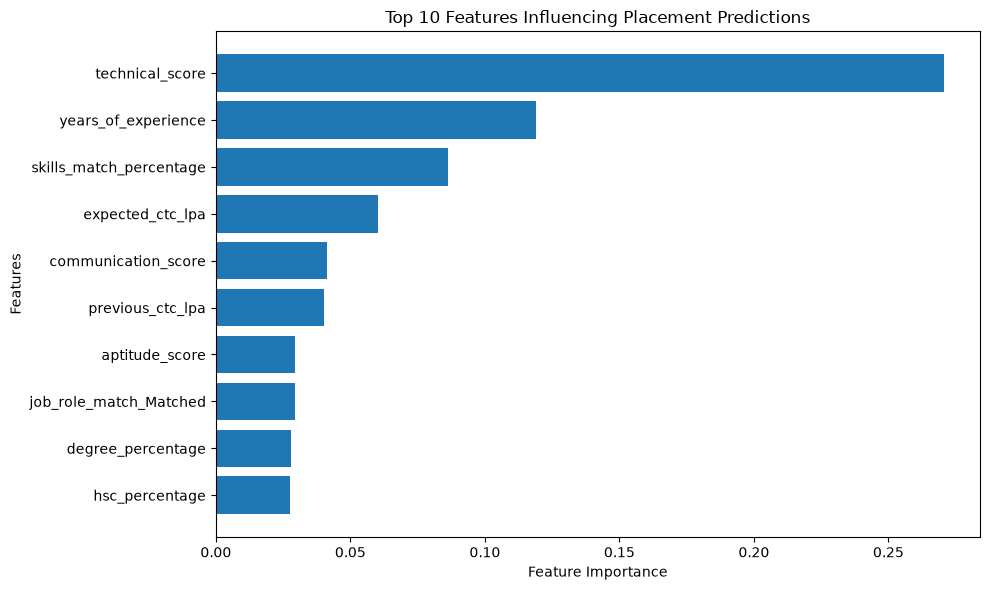

In [129]:
import matplotlib.pyplot as plt

top_10 = importance_df.head(10).copy()

# Remove preprocessing prefixes
top_10['Feature'] = (
    top_10['Feature']
    .str.replace('numerical__', '', regex=False)
    .str.replace('categorical__', '', regex=False)
)

# Reverse order for horizontal chart
top_10 = top_10.sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10['Feature'],
    top_10['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 Features Influencing Placement Predictions')

plt.tight_layout()
plt.show()

2. What do these results tell us?
- Technical score (27.05%): The most influential feature in this model.
- Years of experience (11.90%): The second most influential feature.
- Skills match (8.63%): Matching candidate skills with job requirements has considerable predictive importance.
- Expected CTC (6.03%): Salary expectations contribute to the model's predictions.
- Communication score (4.13%): Communication performance also contributes.
The top three features together account for approximately 47.58% of total feature importance.

One important distinction: Random Forest feature importance tells us how much a feature contributes to the model's decisions. It does not prove that increasing that feature will cause a candidate to get placed. It also doesn't tell us whether the feature increases or decreases placement probability.

In [130]:
top_10['Importance'].sum()

np.float64(0.7319397879602446)

our top 10 features account for approximately 73.19% of the total Random Forest feature importance.

In [132]:
#Step 1 — Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [133]:
#Step 2 — Create a comparison table
model_comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Balanced Random Forest',
        'Tuned Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_tuned)
    ],

    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_tuned)
    ],

    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_tuned)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_tuned)
    ]
})

print(model_comparison)

                    Model  Accuracy  Precision    Recall  F1 Score
0  Original Random Forest    0.8931   0.893446  0.734303  0.806095
1  Balanced Random Forest    0.8937   0.809524  0.848315  0.828465
2     Tuned Random Forest    0.8955   0.805239  0.863516  0.833360


In [134]:
#Let's save the complete tuned pipeline, including both preprocessing and the Random Forest classifier. 
import joblib

final_model = grid_search.best_estimator_

joblib.dump(
    final_model,
    'placement_prediction_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [135]:
#Next step — Verify the saved model 
import joblib

# Load the saved model
loaded_model = joblib.load('placement_prediction_model.pkl')

# Predict using one test candidate
sample_candidate = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_candidate)

print("Predicted status:", prediction[0])

Predicted status: 1


So, the model predicts that this test candidate is Placed.

This confirms that:
1. The .pkl file was saved successfully.
2. The saved pipeline can be loaded again.
3. The loaded model can make predictions.
4. Preprocessing and prediction work together.

In [136]:
#Let's compare the model's prediction with the candidate's actual status. 
actual_status = y_test.iloc[0]

print("Actual status:", actual_status)
print("Predicted status:", prediction[0])

Actual status: 0
Predicted status: 1


Why does this happen?
Your tuned model has 80.52% precision for the Placed class. That means some candidates predicted as Placed will actually be Not Placed.

A machine-learning model does not guarantee 100% correct predictions. It learns patterns from historical data and uses those patterns to predict unseen records.

In [137]:
#Let's inspect the prediction probability 
probabilities = loaded_model.predict_proba(sample_candidate)

print("Probability of Not Placed:", probabilities[0][0])
print("Probability of Placed:", probabilities[0][1])

Probability of Not Placed: 0.4884345238095238
Probability of Placed: 0.5115654761904763


Prediction is not certainty.

The model uses learned patterns from training data. Its probability represents the model's estimated class probability, not a guarantee that the candidate will get placed.

In this example, the difference between the two probabilities is only about 2.31 percentage points.

Where we are in your project

Data preprocessing
Completed

Train/test splitting
Completed

Random Forest training
Completed

Class balancing
Completed

Hyperparameter tuning
Completed

Model evaluation
Completed

Feature importance
Completed

Model saving and loading
Completed

New candidate prediction
Tested

Let's make your saved model reusable. We'll create a Python function that accepts candidate information and returns:
- Predicted placement status.
- Probability of Not Placed.
- Probability of Placed.
This will be useful when we build your final placement prediction application.

In [138]:
#Next step — Build a prediction function 

def predict_placement(candidate_data):

    # Convert candidate information into a DataFrame
    candidate_df = pd.DataFrame([candidate_data])

    # Arrange columns in the same order as training data
    candidate_df = candidate_df[X_train.columns]

    # Predict placement status
    prediction = loaded_model.predict(candidate_df)

    # Get prediction probabilities
    probabilities = loaded_model.predict_proba(candidate_df)

    # Convert numerical prediction into readable status
    if prediction[0] == 1:
        status = "Placed"
    else:
        status = "Not Placed"

    # Display results
    print("Predicted Placement Status:", status)

    print(
        "Probability of Not Placed:",
        round(probabilities[0][0] * 100, 2), "%"
    )

    print(
        "Probability of Placed:",
        round(probabilities[0][1] * 100, 2), "%"
    )

In [139]:
sample_candidate_dict = sample_candidate.iloc[0].to_dict()

predict_placement(sample_candidate_dict)

Predicted Placement Status: Placed
Probability of Not Placed: 48.84 %
Probability of Placed: 51.16 %


In [140]:
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(X_train[col].unique())


Column: gender
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Column: degree_specialization
<StringArray>
[      'Computer Science',            'Electronics',             'Mechanical',
 'Information Technology',                 'Others']
Length: 5, dtype: str

Column: internship_experience
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Column: career_switch_willingness
<StringArray>
['Unknown', 'Not Willing', 'Willing']
Length: 3, dtype: str

Column: relevant_experience
<StringArray>
['Not Relevant', 'Relevant', 'Unknown']
Length: 3, dtype: str

Column: company_tier
<StringArray>
['Tier 2', 'Tier 1', 'Tier 3']
Length: 3, dtype: str

Column: job_role_match
<StringArray>
['Matched', 'Not Matched', 'Unknown']
Length: 3, dtype: str

Column: competition_level
<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

Column: bond_requirement
<StringArray>
['Required', 'Not Required']
Length: 2, dtype: str

Column: layoff_history
<StringArray>
['Yes', 'No', 'Unknown']
Lengt